## LOADING THE LIBRARIES


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    classification_report
)

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

from scipy.stats import chi2_contingency, ttest_ind

import warnings
warnings.filterwarnings("ignore")

### IMPORTING THE DATSET

In [2]:
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [4]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [5]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [7]:
df.nunique()

customerID          7043
gender                 2
SeniorCitizen          2
Partner                2
Dependents             2
tenure                73
PhoneService           2
MultipleLines          3
InternetService        3
OnlineSecurity         3
OnlineBackup           3
DeviceProtection       3
TechSupport            3
StreamingTV            3
StreamingMovies        3
Contract               3
PaperlessBilling       2
PaymentMethod          4
MonthlyCharges      1585
TotalCharges        6531
Churn                  2
dtype: int64

#### trying to understand the dataset 

### DATA cleaning

In [8]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

In [9]:
df.isnull().sum()

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

In [10]:
df=df.dropna()

In [11]:
df.duplicated().sum()

np.int64(0)

### converting churn to 0/1

In [12]:
df["Churn"] = df["Churn"].map({
    "Yes": 1,
    "No": 0
})

In [13]:
df["Churn"].value_counts()

Churn
0    5163
1    1869
Name: count, dtype: int64

### Basic churn analysis

#### overall churn rate

In [14]:
churn_rate = df["Churn"].mean() * 100

print(f"Overall Churn Rate: {churn_rate:.2f}%")

Overall Churn Rate: 26.58%


#### churn distribution

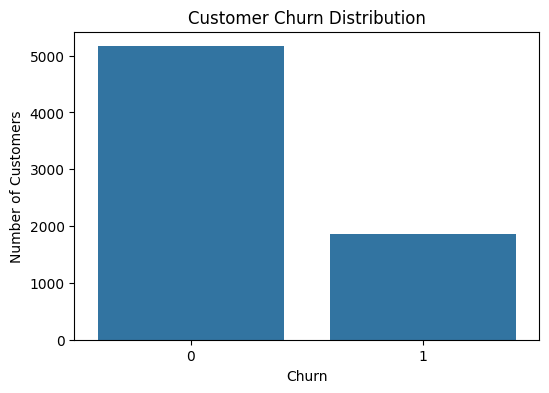

In [15]:
plt.figure(figsize=(6,4))

sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.show()

#### churn by contact

In [16]:
contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

print(contract_churn)

Churn                   0          1
Contract                            
Month-to-month  57.290323  42.709677
One year        88.722826  11.277174
Two year        97.151335   2.848665


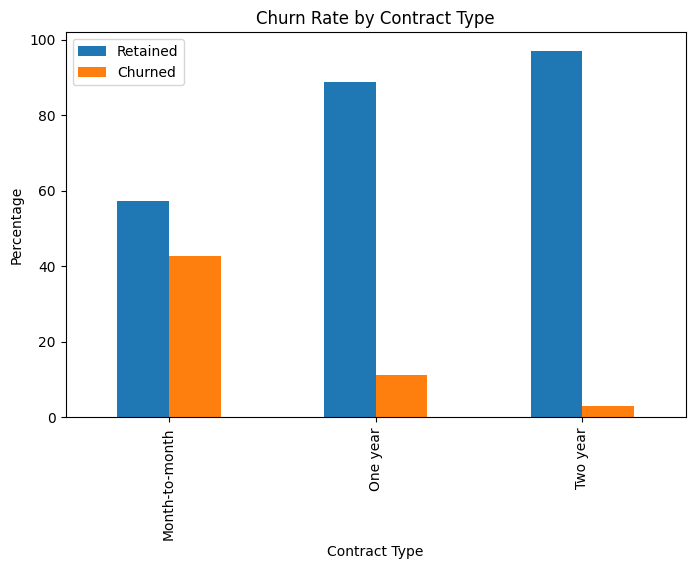

In [17]:
contract_churn.plot(
    kind="bar",
    figsize=(8,5)
)

plt.title("Churn Rate by Contract Type")
plt.ylabel("Percentage")
plt.xlabel("Contract Type")
plt.legend(["Retained", "Churned"])

plt.show()

#### CHURN BY TENURE

In [18]:
df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=[0,12,24,48,72],
    labels=[
        "0-12 Months",
        "13-24 Months",
        "25-48 Months",
        "49-72 Months"
    ]
)

In [19]:
tenure_churn = pd.crosstab(
    df["TenureGroup"],
    df["Churn"],
    normalize="index"
) * 100

print(tenure_churn)

Churn                 0          1
TenureGroup                       
0-12 Months   52.321839  47.678161
13-24 Months  71.289062  28.710938
25-48 Months  79.611041  20.388959
49-72 Months  90.486824   9.513176


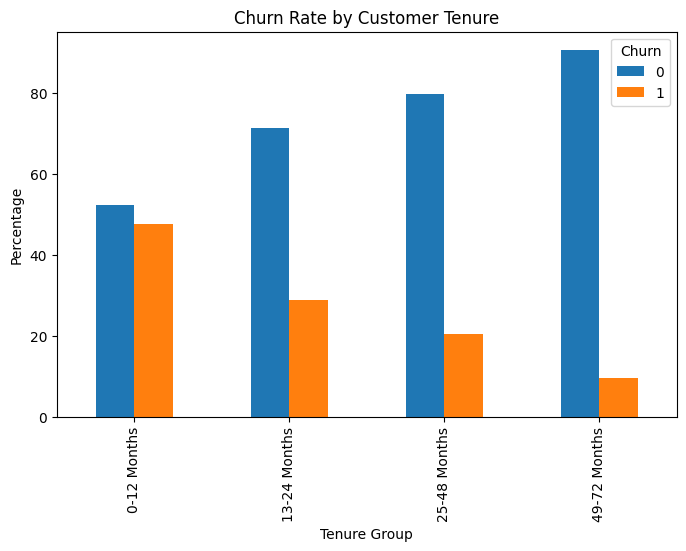

In [20]:
tenure_churn.plot(
    kind="bar",
    figsize=(8,5)
)

plt.title("Churn Rate by Customer Tenure")
plt.ylabel("Percentage")
plt.xlabel("Tenure Group")

plt.show()

#### churn by internet service

In [21]:
internet_churn = pd.crosstab(
    df["InternetService"],
    df["Churn"],
    normalize="index"
) * 100

print(internet_churn)

Churn                    0          1
InternetService                      
DSL              81.001656  18.998344
Fiber optic      58.107235  41.892765
No               92.565789   7.434211


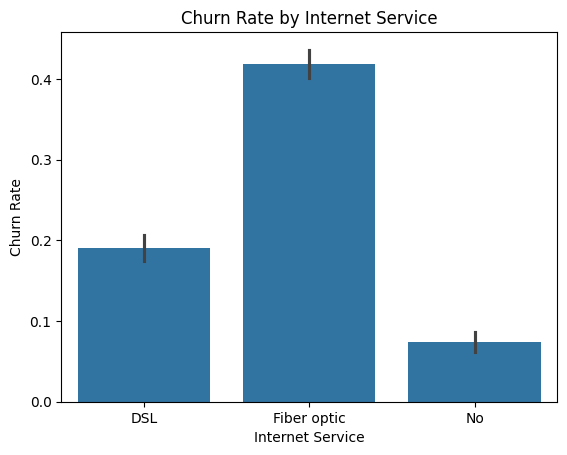

In [22]:
sns.barplot(
    data=df,
    x="InternetService",
    y="Churn"
)

plt.title("Churn Rate by Internet Service")
plt.ylabel("Churn Rate")
plt.xlabel("Internet Service")

plt.show()

#### churn by payment method

In [23]:
payment_churn = pd.crosstab(
    df["PaymentMethod"],
    df["Churn"],
    normalize="index"
) * 100

print(payment_churn)

Churn                              0          1
PaymentMethod                                  
Bank transfer (automatic)  83.268482  16.731518
Credit card (automatic)    84.746877  15.253123
Electronic check           54.714588  45.285412
Mailed check               80.798005  19.201995


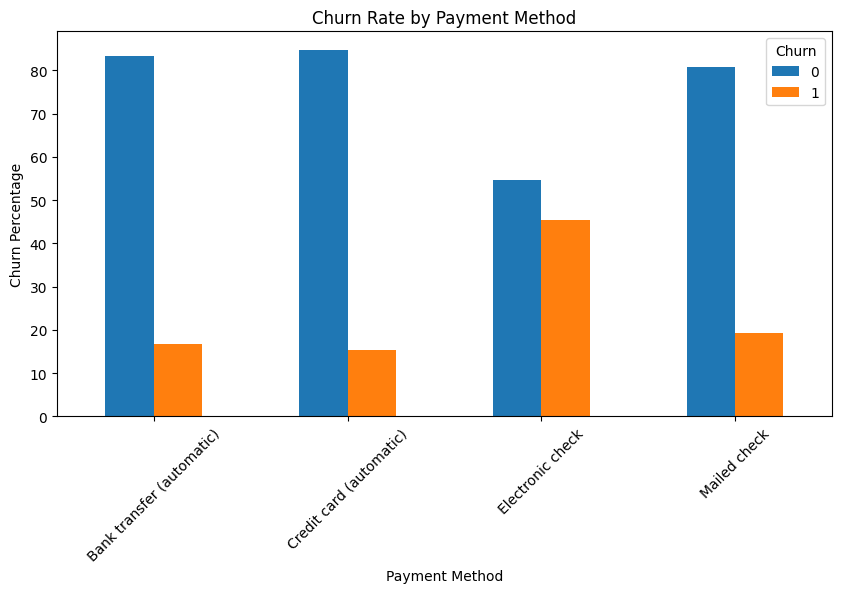

In [24]:
payment_churn.plot(
    kind="bar",
    figsize=(10,5)
)

plt.title("Churn Rate by Payment Method")
plt.ylabel("Churn Percentage")
plt.xlabel("Payment Method")

plt.xticks(rotation=45)

plt.show()

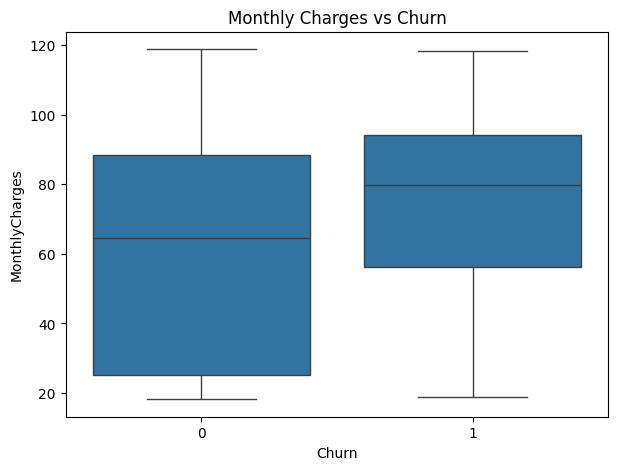

In [25]:
plt.figure(figsize=(7,5))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Monthly Charges vs Churn")

plt.show()

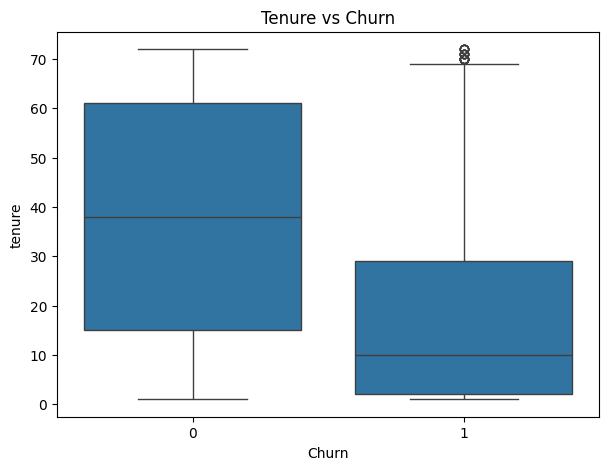

In [26]:
plt.figure(figsize=(7,5))

sns.boxplot(
    data=df,
    x="Churn",
    y="tenure"
)

plt.title("Tenure vs Churn")

plt.show()

### Chi square test

In [27]:
table = pd.crosstab(
    df["Contract"],
    df["Churn"]
)

chi2, p, dof, expected = chi2_contingency(table)

print("Chi-square statistic:", chi2)
print("p-value:", p)

Chi-square statistic: 1179.5458287339445
p-value: 7.326182186265472e-257


In [28]:
if p < 0.05:
    print("Contract type is significantly associated with churn.")
else:
    print("No significant association found.")

Contract type is significantly associated with churn.


### T test

In [29]:
churned = df[df["Churn"] == 1]["MonthlyCharges"]

retained = df[df["Churn"] == 0]["MonthlyCharges"]

t_stat, p_value = ttest_ind(
    churned,
    retained,
    equal_var=False
)

print("T-statistic:", t_stat)
print("p-value:", p_value)

T-statistic: 18.34091879095257
p-value: 2.657357144516046e-72


### Feature engineering

In [30]:
service_columns = [
    "PhoneService",
    "MultipleLines",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies"
]

In [31]:
df["ServiceCount"] = 0

for col in service_columns:
    df["ServiceCount"] += df[col].apply(
        lambda x: 1 if x == "Yes" else 0
    )

In [32]:
df[["ServiceCount", "Churn"]].head()

,ServiceCount,Churn
0,1,0
1,3,0
2,3,1
3,3,0
4,1,1


### Create customer value proxy

In [33]:
df["CustomerValue"] = (
    df["MonthlyCharges"] * df["tenure"]
)

In [34]:
df["AnnualValue"] = df["MonthlyCharges"] * 12

### prepare data for machine learning


In [35]:
df_ml = df.drop(
    ["TenureGroup"],
    axis=1
)

In [36]:
X = df_ml.drop("Churn", axis=1)

y = df_ml["Churn"]

In [37]:
categorical_columns = X.select_dtypes(
    include=["object"]
).columns

numerical_columns = X.select_dtypes(
    exclude=["object"]
).columns

print("Categorical:", list(categorical_columns))
print("Numerical:", list(numerical_columns))

Categorical: ['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Numerical: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'ServiceCount', 'CustomerValue', 'AnnualValue']


### Train-split data

In [38]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

### pre processing line

In [39]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_columns
        ),
        (
            "cat",
            "passthrough",
            categorical_columns
        )
    ]
)

In [40]:
from sklearn.preprocessing import OneHotEncoder

In [41]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_columns
        ),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            categorical_columns
        )
    ]
)

### logistic regression

In [42]:
logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            LogisticRegression(
                max_iter=1000
            )
        )
    ]
)

In [43]:
logistic_model.fit(
    X_train,
    y_train
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](23,)","['customerID','gender','SeniorCitizen',...,'ServiceCount','CustomerValue', 'AnnualValue']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,23
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='pa

In [44]:
y_pred = logistic_model.predict(X_test)

y_prob = logistic_model.predict_proba(
    X_test
)[:,1]

### evaluate logistic regression

In [45]:
print(
    "Accuracy:",
    accuracy_score(y_test, y_pred)
)

print(
    "Precision:",
    precision_score(y_test, y_pred)
)

print(
    "Recall:",
    recall_score(y_test, y_pred)
)

print(
    "F1 Score:",
    f1_score(y_test, y_pred)
)

print(
    "ROC-AUC:",
    roc_auc_score(y_test, y_prob)
)

Accuracy: 0.8038379530916845
Precision: 0.6484848484848484
Recall: 0.5721925133689839
F1 Score: 0.6079545454545454
ROC-AUC: 0.8357504490839721


In [46]:
print(
    classification_report(
        y_test,
        y_pred
    )
)

              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1033
           1       0.65      0.57      0.61       374

    accuracy                           0.80      1407
   macro avg       0.75      0.73      0.74      1407
weighted avg       0.80      0.80      0.80      1407



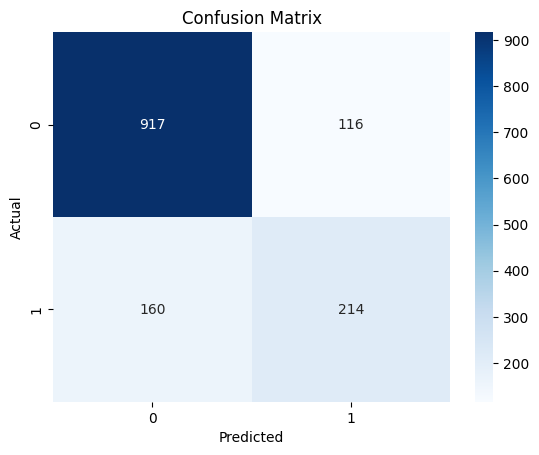

In [47]:
## confusiom matrix
cm = confusion_matrix(
    y_test,
    y_pred
)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.show()

### random forest

In [48]:
rf_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            RandomForestClassifier(
                n_estimators=300,
                random_state=42,
                class_weight="balanced"
            )
        )
    ]
)

In [51]:
rf_model.fit(
    X_train,
    y_train
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](23,)","['customerID','gender','SeniorCitizen',...,'ServiceCount','CustomerValue', 'AnnualValue']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,23
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='pa

In [52]:
rf_pred = rf_model.predict(X_test)

rf_prob = rf_model.predict_proba(
    X_test
)[:,1]

In [53]:
#EVALUATE
print(
    "Accuracy:",
    accuracy_score(y_test, rf_pred)
)

print(
    "Precision:",
    precision_score(y_test, rf_pred)
)

print(
    "Recall:",
    recall_score(y_test, rf_pred)
)

print(
    "F1 Score:",
    f1_score(y_test, rf_pred)
)

print(
    "ROC-AUC:",
    roc_auc_score(y_test, rf_prob)
)

Accuracy: 0.7633262260127932
Precision: 0.5438972162740899
Recall: 0.679144385026738
F1 Score: 0.6040428061831153
ROC-AUC: 0.8235397652856795


### COMPARE MODELS

In [54]:
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, rf_pred)
    ],
    "Precision": [
        precision_score(y_test, y_pred),
        precision_score(y_test, rf_pred)
    ],
    "Recall": [
        recall_score(y_test, y_pred),
        recall_score(y_test, rf_pred)
    ],
    "F1 Score": [
        f1_score(y_test, y_pred),
        f1_score(y_test, rf_pred)
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, y_prob),
        roc_auc_score(y_test, rf_prob)
    ]
})

results

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.803838,0.648485,0.572193,0.607955,0.83575
1,Random Forest,0.763326,0.543897,0.679144,0.604043,0.82354


### Predict Churn Probability for EVERY Customer

In [55]:
df["ChurnProbability"] = rf_model.predict_proba(
    df_ml.drop("Churn", axis=1)
)[:,1]

In [56]:
def risk_category(probability):

    if probability >= 0.70:
        return "High Risk"

    elif probability >= 0.40:
        return "Medium Risk"

    else:
        return "Low Risk"

In [57]:
df["RiskCategory"] = df[
    "ChurnProbability"
].apply(risk_category)

In [59]:
df[
    [
        "ChurnProbability",
        "RiskCategory"
    ]
].head()

,ChurnProbability,RiskCategory
0,0.343333,Low Risk
1,0.023333,Low Risk
2,0.950000,High Risk
3,0.026667,Low Risk
4,0.956667,High Risk


### Risk Distribution

In [60]:
df["RiskCategory"].value_counts()

RiskCategory
Low Risk       4813
High Risk      1741
Medium Risk     478
Name: count, dtype: int64

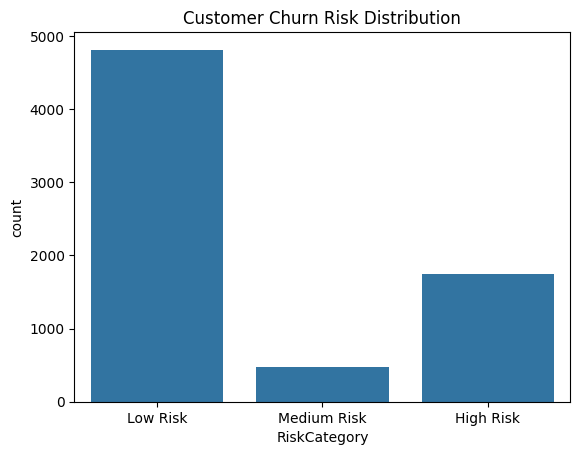

In [61]:
sns.countplot(
    data=df,
    x="RiskCategory",
    order=[
        "Low Risk",
        "Medium Risk",
        "High Risk"
    ]
)

plt.title("Customer Churn Risk Distribution")

plt.show()

### revenue at risk

In [62]:
df["RevenueAtRisk"] = (
    df["MonthlyCharges"]
    * 12
    * df["ChurnProbability"]
)

In [63]:
total_revenue_risk = df[
    "RevenueAtRisk"
].sum()

print(
    f"Estimated Annual Revenue at Risk: "
    f"${total_revenue_risk:,.2f}"
)

Estimated Annual Revenue at Risk: $2,156,710.51


### High-Value High-Risk Customers

In [64]:
df["ValueSegment"] = pd.qcut(
    df["CustomerValue"],
    q=3,
    labels=[
        "Low Value",
        "Medium Value",
        "High Value"
    ]
)

In [65]:
df["PrioritySegment"] = (
    df["RiskCategory"].astype(str)
    + " - "
    + df["ValueSegment"].astype(str)
)


In [66]:
df["PrioritySegment"].value_counts()

PrioritySegment
Low Risk - High Value         1917
Low Risk - Medium Value       1670
Low Risk - Low Value          1226
High Risk - Low Value          901
High Risk - Medium Value       508
High Risk - High Value         332
Medium Risk - Low Value        217
Medium Risk - Medium Value     166
Medium Risk - High Value        95
Name: count, dtype: int64

### Find Your Most Important Customers

In [67]:
priority_customers = df[
    (df["RiskCategory"] == "High Risk") &
    (df["ValueSegment"] == "High Value")
].sort_values(
    "ChurnProbability",
    ascending=False
)

In [68]:
priority_customers[
    [
        "ChurnProbability",
        "MonthlyCharges",
        "tenure",
        "CustomerValue",
        "RevenueAtRisk",
        "Contract",
        "InternetService"
    ]
].head(20)

,ChurnProbability,MonthlyCharges,tenure,CustomerValue,RevenueAtRisk,Contract,InternetService
4719,0.996667,84.90,36,3056.40,1015.404,Month-to-month,Fiber optic
5383,0.990000,84.75,36,3051.00,1006.830,Month-to-month,Fiber optic
6616,0.990000,101.40,43,4360.20,1204.632,Month-to-month,Fiber optic
3775,0.986667,98.40,41,4034.40,1165.056,Month-to-month,Fiber optic
3673,0.986667,101.75,42,4273.50,1204.720,Month-to-month,Fiber optic
3950,0.983333,96.20,49,4713.80,1135.160,Month-to-month,Fiber optic
724,0.980000,94.50,33,3118.50,1111.320,Month-to-month,Fiber optic
3829,0.980000,101.00,43,4343.00,1187.760,Month-to-month,Fiber optic
948,0.980000,99.05,35,3466.75,1164.828,Month-to-month,Fiber optic
1621,0.980000,86.45,35,3025.75,1016.652,Month-to-month,Fiber optic


### Retention Strategy Generator

In [69]:
def retention_strategy(row):

    if (
        row["RiskCategory"] == "High Risk"
        and row["ValueSegment"] == "High Value"
    ):
        return "Personalized retention offer + priority support"

    elif (
        row["RiskCategory"] == "High Risk"
        and row["ValueSegment"] == "Medium Value"
    ):
        return "Discount + service upgrade"

    elif (
        row["RiskCategory"] == "High Risk"
        and row["ValueSegment"] == "Low Value"
    ):
        return "Automated retention campaign"

    elif (
        row["RiskCategory"] == "Medium Risk"
    ):
        return "Engagement campaign + service education"

    else:
        return "Loyalty & cross-sell campaign"

In [70]:
df["RetentionStrategy"] = df.apply(
    retention_strategy,
    axis=1
)

In [71]:
df[
    [
        "ChurnProbability",
        "RiskCategory",
        "ValueSegment",
        "RevenueAtRisk",
        "RetentionStrategy"
    ]
].head(20)

,ChurnProbability,RiskCategory,ValueSegment,RevenueAtRisk,RetentionStrategy
0,0.343333,Low Risk,Low Value,122.982,Loyalty & cross-sell campaign
1,0.023333,Low Risk,Medium Value,15.946,Loyalty & cross-sell campaign
2,0.950000,High Risk,Low Value,613.890,Automated retention campaign
3,0.026667,Low Risk,Medium Value,13.536,Loyalty & cross-sell campaign
4,0.956667,High Risk,Low Value,811.636,Automated retention campaign
5,0.996667,High Risk,Medium Value,1191.814,Discount + service upgrade
6,0.576667,Medium Risk,Medium Value,616.572,Engagement campaign + service education
7,0.396667,Low Risk,Low Value,141.610,Loyalty & cross-sell campaign
8,0.950000,High Risk,High Value,1194.720,Personalized retention offer + priority support
9,0.063333,Low Risk,High Value,42.674,Loyalty & cross-sell campaign


In [72]:
df.to_csv(
    "customer_churn_analysis_final.csv",
    index=False
)

In [73]:
priority_customers.to_csv(
    "high_priority_customers.csv",
    index=False
)